# Неделя 08. Предобработка, новые признаки и Pipeline без утечек

        **Кейс:** подготовить смешанные признаки объявления и построить проверяемый конвейер.
        В таблицу специально добавлен признак из будущего, который нужно исключить.
        Данные полностью синтетические; рынок аренды по ним не оцениваем.

        **Главная идея:** разделяем данные до обучения преобразований; медианы, масштабы и категории
        изучаются только на train. Линейная модель Ridge здесь служит небольшим демонстрационным
        потребителем подготовленных признаков; её математика будет в неделе 09.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import sklearn

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 100})

def locate_week():
    "Работает из practice/, homework/, папки недели и корня репозитория."
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / 'week_08_preprocessing_pipelines'):
            if candidate.name == 'week_08_preprocessing_pipelines' and (candidate / "datasets").is_dir():
                return candidate
    raise FileNotFoundError("Откройте notebook внутри полного клона репозитория.")

WEEK_DIR = locate_week()
DATA_DIR = WEEK_DIR / "datasets"
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Рабочая неделя:", WEEK_DIR.name)


Python: 3.12.14 | NumPy: 2.5.4 | pandas: 3.0.6
Рабочая неделя: week_08_preprocessing_pipelines


## 1. Сначала доступность признаков и разбиение

        Прогноз строится при публикации объявления. `next_month_payment_kzt` появится позднее
        и тесно связан с целью: он запрещён независимо от того, насколько улучшает метрику.
        ID также исключаем. Случайный split подходит для данного независимого синтетического набора;
        реальные повторные объявления потребовали бы группового или временного разделения.


In [2]:
raw = pd.read_csv(DATA_DIR / "rental_listings.csv")
assert raw["listing_id"].is_unique and len(raw) == 400
allowed = ["city", "district", "building_type", "area_m2", "rooms", "age_years", "floor", "balcony"]
X = raw[allowed].copy()
y = raw["rent_kzt"].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
assert "next_month_payment_kzt" not in X_train and "rent_kzt" not in X_train
assert len(X_train) == 320 and len(X_test) == 80
print("scikit-learn:", sklearn.__version__, "| train:", X_train.shape, "| test:", X_test.shape)


scikit-learn: 1.9.1 | train: (320, 8) | test: (80, 8)


## 2. Исследуем train, а test оставляем для оценки

        Описательные таблицы и решения о преобразованиях ниже основаны на train.
        Test не подсказывает медиану заполнения, границы выбросов или выбор признаков.
        Пропуски в числовом и категориальном столбцах требуют разных операций.


,dtype,missing_n,missing_share
city,str,0,0.000000
district,str,0,0.000000
building_type,str,0,0.000000
area_m2,float64,19,0.059375
rooms,int64,0,0.000000
age_years,float64,15,0.046875
floor,int64,0,0.000000
balcony,str,13,0.040625


,area_m2,rooms,age_years,floor
count,301.00,320.00,305.00,320.00
mean,80.93,2.90,25.23,8.13
std,32.11,1.26,14.70,4.47
min,28.14,1.00,0.00,1.00
25%,55.67,2.00,12.00,4.00
50%,78.81,3.00,26.00,8.00
75%,106.22,4.00,38.00,12.00
max,139.50,5.00,50.00,16.00


,train_rent_kzt
count,320.00
mean,211227.85
std,66355.63
min,67112.00
25%,163324.50
50%,208071.00
75%,260081.25
max,364849.00


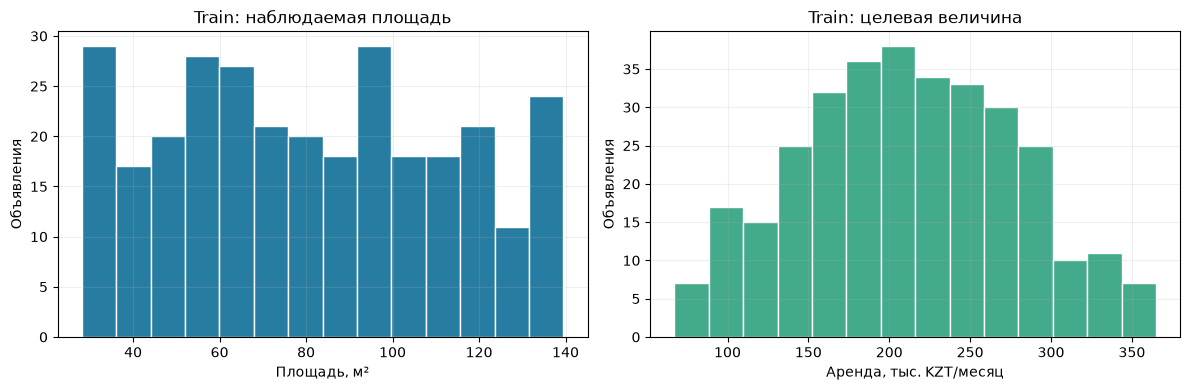

In [3]:
train_profile = pd.DataFrame({"dtype": X_train.dtypes.astype(str),
                              "missing_n": X_train.isna().sum(),
                              "missing_share": X_train.isna().mean()})
display(train_profile)
display(X_train.select_dtypes(include="number").describe().round(2))
display(y_train.describe().round(2).to_frame("train_rent_kzt"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train["area_m2"].dropna(), bins=14, color="#277DA1", edgecolor="white")
axes[0].set(xlabel="Площадь, м²", ylabel="Объявления", title="Train: наблюдаемая площадь")
axes[1].hist(y_train / 1000, bins=14, color="#43AA8B", edgecolor="white")
axes[1].set(xlabel="Аренда, тыс. KZT/месяц", ylabel="Объявления", title="Train: целевая величина")
plt.tight_layout()
plt.show()


## 3. Масштабирование и кодирование: короткий ручной пример

        StandardScaler вычисляет $z=(x-\mu_{train})/\sigma_{train}$.
        Стандартное отклонение используется с `ddof=0`. Для номинальной категории нельзя
        без основания вводить порядок `brick=1, panel=2, monolith=3`; one-hot создаёт отдельные индикаторы.
        Неизвестная категория на новых данных не должна рушить весь прогноз.


In [4]:
toy_train = pd.DataFrame({"area": [30.0, 50.0, 70.0], "type": ["brick", "panel", "brick"]})
scaler_demo = StandardScaler().fit(toy_train[["area"]])
encoded_demo = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(toy_train[["type"]])
display(pd.DataFrame(scaler_demo.transform(toy_train[["area"]]), columns=["scaled_area"]))
display(pd.DataFrame(encoded_demo.transform(toy_train[["type"]]), columns=encoded_demo.get_feature_names_out()))
unknown_demo = encoded_demo.transform(pd.DataFrame({"type": ["new_type"]}))
assert np.allclose(unknown_demo, 0)
assert np.isclose(scaler_demo.mean_[0], 50)


,scaled_area
0,-1.224745
1,0.000000
2,1.224745


,type_brick,type_panel
0,1.0,0.0
1,0.0,1.0
2,1.0,0.0


## 4. Новые признаки: функция без обучения на выборке

        `area_per_room` отражает площадь на комнату, `upper_floor` — этаж ≥10.
        Порог 10 задаётся заранее как учебное условие. Эти преобразования используют только
        признаки текущей строки: они не смотрят на target или статистику соседних наблюдений.
        Если площадь неизвестна, отношение тоже неизвестно — его обработает следующий шаг.


In [5]:
def make_features(frame):
    "Создать признаки в копии DataFrame, сохранив строки и исходные поля."
    result = frame.copy()
    if not result["rooms"].gt(0).all():
        raise ValueError("rooms должно быть положительным для area_per_room")
    result["area_per_room"] = result["area_m2"] / result["rooms"]
    result["upper_floor"] = (result["floor"] >= 10).astype(int)
    return result

engineered_train = make_features(X_train)
display(engineered_train[["area_m2", "rooms", "area_per_room", "floor", "upper_floor"]].head())
assert "area_per_room" not in X_train
assert engineered_train.index.equals(X_train.index)


,area_m2,rooms,area_per_room,floor,upper_floor
3,107.91,3,35.9700,16,1
18,111.05,4,27.7625,7,0
202,137.39,5,27.4780,4,0
250,99.29,4,24.8225,4,0
274,102.52,4,25.6300,15,1


## 5. Числовая и категориальная ветви

        Числа: median imputation → индикаторы пропусков → scaling.
        Категории: most-frequent imputation → one-hot.
        `handle_unknown='ignore'` кодирует новую категорию нулевым вектором в её блоке.
        Это технически позволяет прогноз, но не доказывает качество на новом городе.


In [6]:
numeric_columns = ["area_m2", "rooms", "age_years", "floor", "area_per_room", "upper_floor"]
categorical_columns = ["city", "district", "building_type", "balcony"]
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_columns),
    ("cat", categorical_pipe, categorical_columns),
], remainder="drop")
print("Числовых исходных ветвей:", len(numeric_columns), "| Категориальных:", len(categorical_columns))


Числовых исходных ветвей: 6 | Категориальных: 4


## 6. Полный Pipeline: от исходной строки до прогноза

        `fit` обучает преобразования и модель на train. `predict` выполняет те же
        преобразования с уже выученными параметрами. Нам не нужно вручную кодировать
        новые данные в отдельном блокноте и надеяться на совпадение столбцов.
        Ridge с фиксированным alpha=1 — демонстрационная линейная модель, настройки здесь не подбираем.


In [7]:
pipeline = Pipeline([
    ("features", FunctionTransformer(make_features, validate=False)),
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1.0)),
])
# Определение pipeline ещё не обучает ни медианы, ни категории, ни модель.
assert not hasattr(preprocessor, "transformers_")
print(pipeline)


Pipeline(steps=[('features',
                 FunctionTransformer(func=<function make_features at 0x7f967c5194e0>)),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['area_m2', 'rooms',
                                                   'age_years', 'floor',
                                                   'area_per_room',
                                                   'upper_floor']),
                                                 ('cat',
            

## 7. Короткий предварительный просмотр кросс-валидации

        Кросс-валидацию подробно изучим в неделе 15. Здесь важен один принцип:
        **внутрь CV передаётся весь Pipeline**, чтобы каждый fold учил свои медианы и масштабы.
        Только train делится на три части; внешний test до финальной оценки не используется.
        Отрицательное имя scoring означает соглашение sklearn «больше — лучше», поэтому меняем знак для MAE.


In [8]:
cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
cv_mae = -cross_val_score(pipeline, X_train, y_train, cv=cv,
                          scoring="neg_mean_absolute_error", n_jobs=1)
display(pd.DataFrame({"fold": [1, 2, 3], "validation_mae_kzt": cv_mae}).round(2))
assert np.isfinite(cv_mae).all() and (cv_mae >= 0).all()
pipeline.fit(X_train, y_train)


,fold,validation_mae_kzt
0,1,13334.91
1,2,15403.53
2,3,17152.10


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['city','district','building_type',...,'age_years','floor','balcony']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function mak...x7f967c5194e0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


## 8. Проверяем, что imputer видел только train

        После fit достаём обученную числовую ветвь и независимо вычисляем медианы train.
        Эта проверка способна обнаружить fit на полном наборе или неправильный набор столбцов.
        Проверка формы и конечности подготовленной матрицы ловит пропуски, деление на ноль и несогласованные категории.


In [9]:
fitted_pre = pipeline.named_steps["preprocess"]
fitted_num = fitted_pre.named_transformers_["num"]
medians = fitted_num.named_steps["imputer"].statistics_.copy()
expected_medians = engineered_train[numeric_columns].median().to_numpy()
assert np.allclose(medians, expected_medians)
train_matrix = fitted_pre.transform(engineered_train)
feature_names = fitted_pre.get_feature_names_out()
assert train_matrix.shape[0] == len(X_train)
assert train_matrix.shape[1] == len(feature_names)
assert np.isfinite(train_matrix).all()
display(pd.DataFrame(train_matrix[:5], columns=feature_names).round(2))
print("Матрица train:", train_matrix.shape, "| Все параметры импутации соответствуют train.")


,num__area_m2,num__rooms,num__age_years,num__floor,num__area_per_room,num__upper_floor,num__missingindicator_area_m2,num__missingindicator_age_years,num__missingindicator_area_per_room,cat__city_Aktau,cat__city_Astana,cat__city_Atyrau,cat__district_center,cat__district_outskirts,cat__building_type_brick,cat__building_type_monolith,cat__building_type_panel,cat__balcony_no,cat__balcony_yes
0,0.87,0.08,1.66,1.77,1.21,1.18,-0.25,-0.22,-0.25,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.97,0.88,-0.37,-0.25,-0.21,-0.85,-0.25,-0.22,-0.25,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
2,1.82,1.68,1.10,-0.93,-0.26,-0.85,-0.25,-0.22,-0.25,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
3,0.59,0.88,0.75,-0.93,-0.72,-0.85,-0.25,-0.22,-0.25,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,0.70,0.88,-1.07,1.54,-0.58,1.18,-0.25,-0.22,-0.25,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0


Матрица train: (320, 19) | Все параметры импутации соответствуют train.


## 9. Transform на test не должен менять параметры

        Test преобразуется выученными медианами и категориями. Его собственная средняя после
        scaling не обязана быть нулевой: это нормальный результат, а не повод снова вызвать fit.
        У train и test должно быть одинаковое число признаков в одном и том же порядке.


In [10]:
test_matrix = fitted_pre.transform(make_features(X_test))
assert test_matrix.shape[1] == train_matrix.shape[1]
assert np.isfinite(test_matrix).all()
assert np.array_equal(medians, fitted_num.named_steps["imputer"].statistics_)
test_predictions = pipeline.predict(X_test)
assert test_predictions.shape == (len(X_test),) and np.isfinite(test_predictions).all()
print("Test преобразован без повторного обучения; матрица:", test_matrix.shape)


Test преобразован без повторного обучения; матрица: (80, 19)


## 10. Сравнение с baseline на отложенной части

        $MAE=\frac{1}{n}\sum_i|y_i-\hat y_i|$ измеряется в KZT/месяц.
        Baseline предсказывает медиану train для каждого объявления. Сравниваем оба метода
        на одних и тех же 80 test-строках; после просмотра test не меняем признаки или настройки.
        R² — дополнительная относительная мера, которая может быть отрицательной для плохого прогноза.


In [11]:
baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
comparison = pd.DataFrame([
    {"method": "Train median baseline", "mae_kzt": mean_absolute_error(y_test, baseline_predictions),
     "r2": r2_score(y_test, baseline_predictions)},
    {"method": "Pipeline + Ridge", "mae_kzt": mean_absolute_error(y_test, test_predictions),
     "r2": r2_score(y_test, test_predictions)},
])
display(comparison.round(3))
manual_mae = np.mean(np.abs(y_test.to_numpy() - test_predictions))
assert np.isclose(manual_mae, comparison.loc[1, "mae_kzt"])
assert np.allclose(baseline_predictions, y_train.median())


,method,mae_kzt,r2
0,Train median baseline,53287.525,-0.003
1,Pipeline + Ridge,18182.511,0.881


## 11. Диагностика и новая категория

        Диагональ actual=predicted помогает увидеть систематические ошибки; распределение
        абсолютной ошибки показывает разброс. Эти картинки описывают один учебный test.
        Отдельная искусственная строка с новым городом проверяет устойчивость API, не качество модели в этом городе.


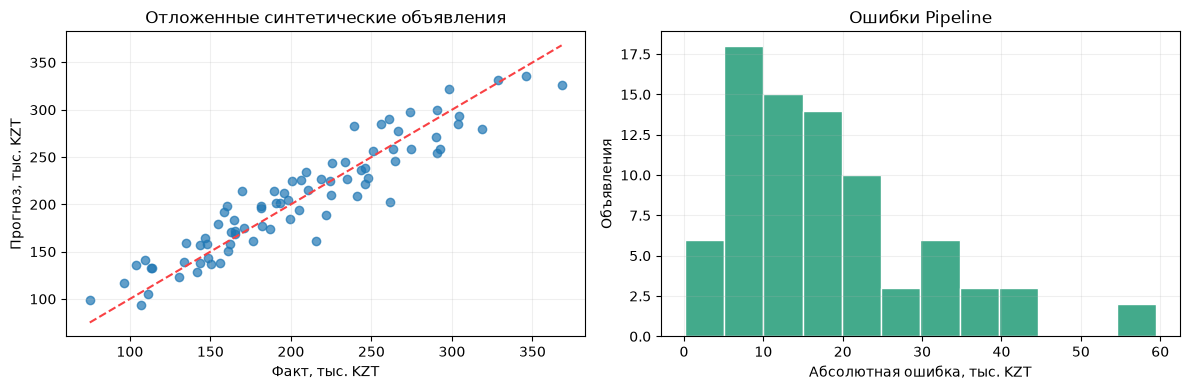

Новая категория обработана; качество вне обучающих категорий отдельно не оценено.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test / 1000, test_predictions / 1000, alpha=0.7)
bounds = np.array([min(y_test.min(), test_predictions.min()), max(y_test.max(), test_predictions.max())]) / 1000
axes[0].plot(bounds, bounds, "--", color="#F94144")
axes[0].set(xlabel="Факт, тыс. KZT", ylabel="Прогноз, тыс. KZT", title="Отложенные синтетические объявления")
axes[1].hist(np.abs(y_test - test_predictions) / 1000, bins=12, color="#43AA8B", edgecolor="white")
axes[1].set(xlabel="Абсолютная ошибка, тыс. KZT", ylabel="Объявления", title="Ошибки Pipeline")
plt.tight_layout()
plt.show()
new_listing = X_test.iloc[[0]].copy()
new_listing["city"] = "NewCity"
prediction_new = pipeline.predict(new_listing)
assert prediction_new.shape == (1,) and np.isfinite(prediction_new).all()
assert np.array_equal(medians, fitted_num.named_steps["imputer"].statistics_)
print("Новая категория обработана; качество вне обучающих категорий отдельно не оценено.")


## 12. Миниатюрная демонстрация утечки статистики

        На трёх train-значениях среднее равно 2. Если незаметно добавить test=100 до fit,
        среднее станет 26,5. Даже без target предобработка начала использовать будущее.
        Ниже намеренно показан неправильный fit только на отдельном игрушечном массиве;
        основной pipeline выше такого шага не выполняет.


In [13]:
toy_history = np.array([[0.0], [2.0], [4.0]])
toy_future = np.array([[100.0]])
correct_scaler = StandardScaler().fit(toy_history)
leaked_scaler = StandardScaler().fit(np.vstack([toy_history, toy_future]))  # Намеренный антипример.
display(pd.DataFrame({"fit_data": ["train only", "train + future (incorrect)"],
                      "learned_mean": [correct_scaler.mean_[0], leaked_scaler.mean_[0]]}))
assert correct_scaler.mean_[0] == 2 and leaked_scaler.mean_[0] == 26.5


,fit_data,learned_mean
0,train only,2.0
1,train + future (incorrect),26.5


## Перед домашней работой

        Объясните, где вызван каждый fit и какие строки он мог видеть. Назовите два различных
        вида утечки: будущий платёж как признак и статистика полного датасета до split.
        Pipeline помогает соблюдать границы, но сам не распознаёт недопустимые бизнес-признаки.
        Для промышленного применения ещё понадобятся схема входа, оценка новых групп и мониторинг.

        Домашняя работа: [Homework Week 08](../homework/Homework_Week_08.md).


## Документация и дальнейшее чтение

- [scikit-learn: предотвращение утечек](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: ColumnTransformer со смешанными типами](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html)
- [scikit-learn: Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [scikit-learn: OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)

Код, объяснения и синтетические примеры в этой лабораторной подготовлены для курса; это не копия университетского ноутбука. Дополнительные лекции находятся в `../presentations/`. Документация проверена 18 октября 2026 года; версии среды закреплены на уровне репозитория.
